# NVFP4 with SGLang: Prefix Reuse and Structured Output

This notebook serves an NVFP4 model with [SGLang](https://github.com/sgl-project/sglang) and asks it many questions about one long document, the way a document Q&A app would. It shows three things:

- **NVFP4 in SGLang**: how much memory the weights take and how much is left for KV cache.
- **RadixAttention**: every question shares the document prefix, so only the first request processes the document.
- **Structured generation**: answers follow a JSON schema and are checked against the document.

The model is [Gemma 4 31B IT](https://huggingface.co/google/gemma-4-31B-it), Google DeepMind's open model released under Apache 2.0, in NVIDIA's NVFP4 checkpoint [`nvidia/Gemma-4-31B-IT-NVFP4`](https://huggingface.co/nvidia/Gemma-4-31B-IT-NVFP4) (about 30 GiB), quantized with [Model Optimizer](https://github.com/NVIDIA/Model-Optimizer). The MLP weights and activations are in 4-bit NVFP4, so those layers run on Blackwell's FP4 tensor cores.

It runs on one [NVIDIA DGX Spark](https://www.nvidia.com/en-us/products/workstations/dgx-spark/), whose GB10 GPU shares 128 GB of unified memory with the CPU.

Prerequisites:
- 1x NVIDIA DGX Spark running DGX OS, which includes Docker and the NVIDIA Container Toolkit
- Jupyter on the Spark, or connected through [NVIDIA Sync](https://build.nvidia.com/spark/connect-to-your-spark/sync)
- About 40 GB of free disk space

## Table of Contents

1. **Environment setup**: container image, client dependencies, hardware check
2. **Serve the NVFP4 checkpoint**: launch SGLang and the flags it uses
3. **Connect to the server**: readiness check, memory split, a timed request
4. **The application**: one long document and the questions about it
5. **RadixAttention**: cold and warm requests, and what breaks a cache hit
6. **Structured generation**: schema-valid answers, checked against the document
7. **The complete workflow**: memory and end-to-end time, with and without prefix reuse
8. **Cleanup and next steps**

## Environment setup

### Pull the SGLang container

NVIDIA's SGLang container from NGC includes an Arm build for DGX Spark:

```shell
docker pull nvcr.io/nvidia/sglang:26.10-py3
```

### Install client dependencies

The notebook is only a client: `openai` sends requests, `jsonschema` validates answers, and `matplotlib` draws the chart.

In [1]:
%pip install -q openai==2.38.0 jsonschema matplotlib


[notice] A new release of pip is available: 25.2 -> 26.3
[notice] To update, run: pip3.13 install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


### Check the GPU and disk

> **Expected output:** `NVIDIA GB10`, with `memory.total` shown as `[N/A]` or `Not Supported`, because the GPU has no memory of its own and shares the system memory that `free -g` reports. Then free space where your Hugging Face cache lives.

In [2]:
!nvidia-smi --query-gpu=name,memory.total,driver_version --format=csv
!free -g
!df -h ~/.cache/huggingface 2>/dev/null || df -h ~

name, memory.total [MiB], driver_version
NVIDIA GB10, [N/A], 580.95.05
               total        used        free      shared  buff/cache   available
Mem:             119           8         103           0           8         110
Swap:             15           0          15
Filesystem      Size  Used Avail Use% Mounted on
/dev/nvme0n1p2  3.7T  762G  2.8T  22% /


## Serve the NVFP4 checkpoint

### Launch the container

Open a terminal on the Spark and start a shell in the SGLang container. `--network host` makes the server reachable from the notebook at `localhost:30000`, and the mount reuses downloaded weights across runs.

```shell
docker run --rm -it \
  --gpus all \
  --network host --ipc host \
  -v ~/.cache/huggingface:/root/.cache/huggingface \
  --entrypoint /bin/bash \
  nvcr.io/nvidia/sglang:26.10-py3
```

### Start the server

Run this inside the container. The first launch takes several minutes while about 30 GiB of weights download and load, kernels compile, and CUDA graphs are captured. Progress can sit at `0%` during this.

```shell
sglang serve \
  --model-path nvidia/Gemma-4-31B-IT-NVFP4 \
  --served-model-name gemma-4-31b \
  --quantization modelopt_fp4 \
  --kv-cache-dtype fp8_e4m3 \
  --attention-backend triton \
  --context-length 65536 \
  --mem-fraction-static 0.75 \
  --grammar-backend xgrammar \
  --enable-cache-report \
  --enable-metrics \
  --host 0.0.0.0 \
  --port 30000
```

| Flag | Purpose |
|---|---|
| `--quantization modelopt_fp4` | Load the NVFP4 checkpoint |
| `--kv-cache-dtype fp8_e4m3` | The KV cache format the checkpoint declares |
| `--attention-backend triton` | SGLang's usual attention backend for Gemma 4 |
| `--context-length 65536` | Room for the document and the answer |
| `--mem-fraction-static 0.75` | Share of memory for weights plus KV cache. The rest covers activations, CUDA graphs, and the OS |
| `--grammar-backend xgrammar` | Enforces the JSON schema (SGLang's default) |
| `--enable-cache-report` | Adds `cached_tokens` to each response's `usage` |
| `--enable-metrics` | Exposes memory and cache counters on `/metrics` |

Prefix caching is on by default. `--disable-radix-cache` turns it off.

> **Note:** On DGX Spark, the OS page cache uses the same memory as the GPU. If the server fails to allocate memory even though the model should fit, stop it, run `sudo sh -c 'sync; echo 3 > /proc/sys/vm/drop_caches'` on the host, and start it again.

## Connect to the server

Run this after starting `sglang serve`. It waits until the model is loaded, then prints what the server is running.

> **Expected output:** Dots while the model loads, then `Server is ready` with `nvidia/Gemma-4-31B-IT-NVFP4` and `modelopt_fp4`.

In [3]:
import json, re, statistics, time, urllib.request

from openai import OpenAI

HOST = "http://127.0.0.1:30000"
MODEL = "gemma-4-31b"
client = OpenAI(base_url=f"{HOST}/v1", api_key="EMPTY", timeout=600)


def get(path):
    with urllib.request.urlopen(f"{HOST}{path}", timeout=30) as response:
        return response.read().decode()


def flush_cache():
    """Empty the radix cache, so the next request starts cold."""
    request = urllib.request.Request(f"{HOST}/flush_cache?timeout=30", method="POST")
    urllib.request.urlopen(request, timeout=60).close()


print("Waiting for server", end="", flush=True)
while True:
    try:
        if MODEL in get("/v1/models"):
            break
    except OSError:
        pass
    print(".", end="", flush=True)
    time.sleep(15)

info = json.loads(get("/get_server_info"))
print(f"\nServer is ready: {info.get('model_path')}, quantization {info.get('quantization')},"
      f" KV cache {info.get('kv_cache_dtype')}")

Waiting for server
Server is ready: nvidia/Gemma-4-31B-IT-NVFP4, quantization modelopt_fp4, KV cache fp8_e4m3


### Memory split

SGLang reserves a fixed share of memory at startup (`--mem-fraction-static`), loads the weights, and gives the rest to the KV cache. `/metrics` reports the weights, the KV cache, and how many tokens the KV cache holds. That capacity limits how much shared context the radix cache can keep.

> **What to look for:** How the reservation splits. The weights take a fixed amount, and what is left becomes KV cache. The token capacity is the number to keep in mind, since it bounds how many documents the radix cache can hold at once.

In [4]:
def metrics():
    """Prometheus metrics from /metrics, summed across label sets."""
    totals = {}
    for line in get("/metrics").splitlines():
        if line and not line.startswith("#"):
            series, _, value = line.rpartition(" ")
            name = series.split("{")[0]
            totals[name] = totals.get(name, 0.0) + float(value)
    return totals


m = metrics()
weights_gb = m["sglang:weight_memory_usage_gb"]
kv_cache_gb = m["sglang:kv_cache_memory_usage_gb"]
kv_cache_tokens = int(m["sglang:max_total_num_tokens"])
print(f"Weights:           {weights_gb:.1f} GB")
print(f"KV cache:          {kv_cache_gb:.1f} GB")
print(f"KV cache capacity: {kv_cache_tokens:,} tokens")

Weights:           36.6 GB
KV cache:          40.4 GB
KV cache capacity: 117,561 tokens


### One timed request

`ask` streams one request and records time to first token (TTFT), total latency, prompt tokens, and how many of them came from the radix cache. TTFT is where prefix reuse shows: before the first output token, the server runs prefill on every prompt token it has not cached.

Sampling is greedy (`temperature=0`), which suits extraction. The cell ends with a short warmup request.

In [5]:
def ask(messages, max_tokens=256, response_format=None):
    """Stream one chat request and return its text, timing, and cache reuse."""
    extra = {"response_format": response_format} if response_format else {}
    start = time.perf_counter()
    ttft = None
    usage = None
    parts = []
    stream = client.chat.completions.create(
        model=MODEL, messages=messages, temperature=0, max_tokens=max_tokens,
        stream=True, stream_options={"include_usage": True}, **extra,
    )
    for chunk in stream:
        if chunk.usage:
            usage = chunk.usage
        if chunk.choices and chunk.choices[0].delta.content:
            if ttft is None:
                ttft = time.perf_counter() - start
            parts.append(chunk.choices[0].delta.content)
    details = usage.prompt_tokens_details
    return {
        "text": "".join(parts),
        "ttft_s": ttft,
        "latency_s": time.perf_counter() - start,
        "prompt_tokens": usage.prompt_tokens,
        "cached_tokens": details.cached_tokens if details else 0,
    }


print(ask([{"role": "user", "content": "Hello!"}], max_tokens=32)["text"])

Hello! How can I help you today?


## The application

A user uploads a long document, and the app asks a series of questions about it. Every request carries the full document, and every answer has to be machine-readable.

The document is the paper that introduced SGLang and RadixAttention, [SGLang: Efficient Execution of Structured Language Model Programs](https://arxiv.org/abs/2312.07104) (Zheng et al., 2024), fetched from arXiv as plain text. It is pinned to v2, so it is the same for everyone, and long enough that processing it dominates the wait for the first token. Each question has a known answer in the paper, so answers can be graded automatically. The last question asks about NVFP4, which the paper never mentions.

> **Note:** To use your own document, replace `DOCUMENT` and `QUESTIONS`. Each `expected` is a list of strings the answer must contain, or `None` if the document cannot answer the question.

In [6]:
from html.parser import HTMLParser

PAPER_URL = "https://arxiv.org/html/2312.07104v2"


class TextExtractor(HTMLParser):
    """Visible text from an arXiv HTML paper, with a blank line between blocks."""

    BLOCKS = {"p", "h1", "h2", "h3", "h4", "h5", "h6", "li", "tr", "figcaption"}
    HIDDEN = {"script", "style", "nav", "header", "footer", "annotation", "annotation-xml"}

    def __init__(self):
        super().__init__()
        self.parts = []
        self.hidden = 0

    def handle_starttag(self, tag, attrs):
        if tag in self.HIDDEN:
            self.hidden += 1
        elif tag in self.BLOCKS:
            self.parts.append("\n\n")

    def handle_endtag(self, tag):
        if tag in self.HIDDEN:
            self.hidden -= 1

    def handle_data(self, data):
        if not self.hidden:
            self.parts.append(data)


extractor = TextExtractor()
with urllib.request.urlopen(PAPER_URL, timeout=60) as response:
    extractor.feed(response.read().decode())
text = re.sub(r"[ \t]+", " ", "".join(extractor.parts))
text = re.sub(r"\s*\n\s*\n\s*", "\n\n", text)
DOCUMENT = text[text.index("Abstract"):].strip()  # skip the arXiv page header

QUESTIONS = [
    {"question": "According to the abstract, how much higher throughput does SGLang achieve than existing systems?",
     "expected": ["6.4"]},
    {"question": "When GPU memory fills up, which nodes of the radix tree does RadixAttention evict first?",
     "expected": ["leaf"]},
    {"question": "Which GPUs were most of the experiments run on?",
     "expected": ["A10G"]},
    {"question": "Which version of vLLM was used as a baseline?",
     "expected": ["0.2.5"]},
    {"question": "What RadixAttention cache hit rate was observed for Vicuna-33B in production?",
     "expected": ["74.1"]},
    {"question": "What technique does SGLang use to speed up constrained decoding?",
     "expected": ["compressed finite state machine"]},
    {"question": "What accuracy does the paper report for NVFP4 quantization?",
     "expected": None},
]

print(f"{len(DOCUMENT):,} characters\n")
print(DOCUMENT[:600], "...\n")
for q in QUESTIONS:
    print("-", q["question"])

71,551 characters

Abstract

Large language models (LLMs) are increasingly used for complex tasks that require multiple generation calls, advanced prompting techniques, control flow, and structured inputs/outputs. However, efficient systems are lacking for programming and executing these applications. We introduce SGLang, a system for efficient execution of complex language model programs. SGLang consists of a frontend language and a runtime. The frontend simplifies programming with primitives for generation and parallelism control. The runtime accelerates execution with novel optimizations like RadixAttention f ...

- According to the abstract, how much higher throughput does SGLang achieve than existing systems?
- When GPU memory fills up, which nodes of the radix tree does RadixAttention evict first?
- Which GPUs were most of the experiments run on?
- Which version of vLLM was used as a baseline?
- What RadixAttention cache hit rate was observed for Vicuna-33B in production?
- What 

### How the prompt is laid out

Every request is the system prompt, then the document, then the question, so everything before the question is identical across requests. That shared beginning is what the radix cache reuses.

In [7]:
SYSTEM_PROMPT = (
    "You answer questions about the document the user provides. "
    "Use only information in the document. Keep answers short."
)


def doc_messages(question, instruction=None, system=SYSTEM_PROMPT, question_first=False):
    """Chat messages for one question about DOCUMENT."""
    document = f"<document>\n{DOCUMENT}\n</document>"
    ask_part = f"{instruction}\n\nQuestion: {question}" if instruction else f"Question: {question}"
    parts = [ask_part, document] if question_first else [document, ask_part]
    return [
        {"role": "system", "content": system},
        {"role": "user", "content": "\n\n".join(parts)},
    ]

## RadixAttention

Before the first output token, the model runs **prefill**: it processes every prompt token and stores their keys and values in the KV cache. For a long document, prefill is most of the wait.

RadixAttention keeps that KV cache after a request finishes, in a radix tree keyed by token IDs. Each new request reuses the longest matching prefix and runs prefill only on the rest. A hit needs two things:

- **Tokens match from the start.** Reuse stops at the first token that differs.
- **The entries are still cached.** Under memory pressure SGLang evicts the least recently used entries, so a larger KV cache keeps more documents warm. This is where NVFP4's smaller weights help.

### Cold, then warm

The cell below empties the cache, then asks every question in order. The first request processes the whole document, and the rest reuse it.

> **What to look for:** The first row takes nothing from cache and has the slowest TTFT. Once the document is cached, later rows take most or all of their prompt from cache and their TTFT drops sharply. Reuse can build up over the first couple of requests, depending on how the server splits a long prefill into chunks.

In [8]:
from IPython.display import Markdown, display


def show_runs(runs, labels):
    rows = ["| Request | Prompt tokens | From cache | TTFT (ms) | Total (s) |", "|---|---|---|---|---|"]
    for run, label in zip(runs, labels):
        rows.append(f"| {label} | {run['prompt_tokens']:,} | {run['cached_tokens']:,} |"
                    f" {run['ttft_s'] * 1000:,.0f} | {run['latency_s']:.2f} |")
    display(Markdown("\n".join(rows)))


flush_cache()
radix_runs = [ask(doc_messages(q["question"]), max_tokens=128) for q in QUESTIONS]
show_runs(radix_runs, [q["question"] for q in QUESTIONS])

cold_ttft = radix_runs[0]["ttft_s"]
warm_ttft = statistics.median(r["ttft_s"] for r in radix_runs[1:])
print(f"Cold TTFT {cold_ttft * 1000:,.0f} ms, warm TTFT {warm_ttft * 1000:,.0f} ms, {cold_ttft / warm_ttft:.1f}x faster\n")
for r in radix_runs:
    print("-", r["text"].strip())

| Request | Prompt tokens | From cache | TTFT (ms) | Total (s) |
|---|---|---|---|---|
| According to the abstract, how much higher throughput does SGLang achieve than existing systems? | 18,121 | 0 | 20,740 | 24.39 |
| When GPU memory fills up, which nodes of the radix tree does RadixAttention evict first? | 18,123 | 16,384 | 2,281 | 4.90 |
| Which GPUs were most of the experiments run on? | 18,113 | 18,094 | 336 | 3.82 |
| Which version of vLLM was used as a baseline? | 18,115 | 18,095 | 338 | 2.52 |
| What RadixAttention cache hit rate was observed for Vicuna-33B in production? | 18,122 | 18,094 | 331 | 3.83 |
| What technique does SGLang use to speed up constrained decoding? | 18,116 | 18,095 | 329 | 7.62 |
| What accuracy does the paper report for NVFP4 quantization? | 18,115 | 18,095 | 332 | 2.81 |

Cold TTFT 20,740 ms, warm TTFT 334 ms, 62.1x faster

- SGLang achieves up to 6.4× higher throughput compared to state-of-the-art inference systems.
- RadixAttention uses an LRU eviction policy that evicts the least recently used leaf first.
- Most experiments were run on AWS EC2 G5 instances equipped with NVIDIA A10G GPUs (24GB).
- vLLM v0.2.5 was used as a baseline.
- The observed RadixAttention cache hit rate for Vicuna-33B in production was 74.1%.
- SGLang uses a **compressed finite state machine** to speed up constrained decoding. This technique analyzes the finite state machine and compresses adjacent singular-transition edges into single edges, allowing the system to decode multiple tokens at once in a single forward pass.
- The provided document does not contain any information regarding NVFP4 quantization or its accuracy.


### What breaks a cache hit

Each case empties the cache, primes it with one normal request, then sends a variation:

- **New question, same prefix**: the control.
- **Question before the document**: the match ends at the new question, before the document.
- **Timestamp in the system prompt**: the match ends at the timestamp, at the very start.

Put what is shared first and what varies last, and keep timestamps, user names, and request IDs out of the shared part.

> **What to look for:** The control takes most of its prompt from cache. The other two reuse little or nothing, and their TTFT goes back to the cold level.

In [9]:
from datetime import datetime

probe = "Which universities are the authors affiliated with?"
variants = {
    "New question, same prefix": doc_messages(probe),
    "Question before the document": doc_messages(probe, question_first=True),
    "Timestamp in the system prompt": doc_messages(
        probe, system=f"Current time: {datetime.now().isoformat()}\n{SYSTEM_PROMPT}"
    ),
}

breaker_runs = []
for messages in variants.values():
    flush_cache()
    ask(doc_messages(QUESTIONS[0]["question"]), max_tokens=16)  # prime the cache
    breaker_runs.append(ask(messages, max_tokens=64))

show_runs(breaker_runs, list(variants))

| Request | Prompt tokens | From cache | TTFT (ms) | Total (s) |
|---|---|---|---|---|
| New question, same prefix | 18,111 | 16,384 | 2,080 | 4.12 |
| Question before the document | 18,111 | 0 | 22,129 | 24.17 |
| Timestamp in the system prompt | 18,142 | 0 | 20,797 | 22.84 |

## Structured generation

The answers above vary in shape, so code that consumes them has to guess. A JSON schema fixes the shape: SGLang compiles it into a grammar with xgrammar and, at each decoding step, masks out tokens that would break it. Unless `max_tokens` cuts a reply off, it always parses and matches the schema.

The schema has three fields:

- `answer_found`: whether the document answers the question, so a missing fact does not have to be invented
- `answer`: the short answer
- `evidence`: the sentence or table row the answer came from, copied verbatim

In [10]:
from jsonschema import Draft202012Validator

ANSWER_SCHEMA = {
    "type": "object",
    "properties": {
        "answer_found": {"type": "boolean"},
        "answer": {"type": "string"},
        "evidence": {"type": "string"},
    },
    "required": ["answer_found", "answer", "evidence"],
    "additionalProperties": False,
}

RESPONSE_FORMAT = {
    "type": "json_schema",
    "json_schema": {"name": "document_answer", "schema": ANSWER_SCHEMA, "strict": True},
}

JSON_INSTRUCTION = (
    "Reply with a JSON object with three keys: "
    "answer_found (true if the document answers the question, otherwise false), "
    "answer (a short answer, or an empty string if not found), and "
    "evidence (the exact sentence or table row from the document that supports the answer, "
    "copied verbatim, or an empty string if not found)."
)

validator = Draft202012Validator(ANSWER_SCHEMA)


def parse_answer(text):
    """Returns (parsed object or None, problem)."""
    try:
        parsed = json.loads(text)
    except json.JSONDecodeError as error:
        return None, f"not JSON ({error.msg})"
    errors = list(validator.iter_errors(parsed))
    if errors:
        return None, f"fails schema: {errors[0].message}"
    return parsed, None


def ask_json(question, schema=True):
    run = ask(doc_messages(question["question"], JSON_INSTRUCTION), max_tokens=512,
              response_format=RESPONSE_FORMAT if schema else None)
    run["parsed"], run["problem"] = parse_answer(run["text"])
    return run

### Without the schema

The same JSON instruction, with nothing enforcing it.

> **What to look for:** Whether each reply parses. Models often wrap JSON in a Markdown code fence or add a sentence before it, and `json.loads` rejects both. How many pass varies by model and prompt. Without the schema, nothing guarantees a valid reply.

In [11]:
for q in QUESTIONS:
    run = ask_json(q, schema=False)
    print("VALID  " if run["parsed"] else f"INVALID ({run['problem']})", q["question"])

INVALID (not JSON (Expecting value)) According to the abstract, how much higher throughput does SGLang achieve than existing systems?
INVALID (not JSON (Expecting value)) When GPU memory fills up, which nodes of the radix tree does RadixAttention evict first?
INVALID (not JSON (Expecting value)) Which GPUs were most of the experiments run on?
INVALID (not JSON (Expecting value)) Which version of vLLM was used as a baseline?
INVALID (not JSON (Expecting value)) What RadixAttention cache hit rate was observed for Vicuna-33B in production?
INVALID (not JSON (Expecting value)) What technique does SGLang use to speed up constrained decoding?
INVALID (not JSON (Expecting value)) What accuracy does the paper report for NVFP4 quantization?


### With the schema

The same requests with `response_format` set. The prompt is unchanged, so the document prefix is still reused: prefix caching and constrained decoding work on the same request.

> **What to look for:** Every reply is valid, and the `From cache` column stays high. Replies take longer than the plain answers above because the `evidence` field quotes whole sentences.

In [12]:
structured_runs = [ask_json(q) for q in QUESTIONS]
show_runs(structured_runs, [q["question"] for q in QUESTIONS])
print(f"Schema-valid replies: {sum(r['parsed'] is not None for r in structured_runs)}/{len(QUESTIONS)}")
print(json.dumps(structured_runs[0]["parsed"], indent=2))

| Request | Prompt tokens | From cache | TTFT (ms) | Total (s) |
|---|---|---|---|---|
| According to the abstract, how much higher throughput does SGLang achieve than existing systems? | 18,188 | 18,187 | 334 | 15.21 |
| When GPU memory fills up, which nodes of the radix tree does RadixAttention evict first? | 18,190 | 18,189 | 324 | 8.93 |
| Which GPUs were most of the experiments run on? | 18,180 | 18,179 | 325 | 8.35 |
| Which version of vLLM was used as a baseline? | 18,182 | 18,181 | 326 | 7.33 |
| What RadixAttention cache hit rate was observed for Vicuna-33B in production? | 18,189 | 18,188 | 329 | 10.69 |
| What technique does SGLang use to speed up constrained decoding? | 18,183 | 18,182 | 326 | 9.96 |
| What accuracy does the paper report for NVFP4 quantization? | 18,182 | 18,181 | 331 | 2.51 |

Schema-valid replies: 7/7
{
  "answer_found": true,
  "answer": "Up to 6.4\u00d1 higher throughput",
  "evidence": "Experiments show that SGLang achieves up to 6.4\u00d1 higher throughput compared to state-of-the-art inference systems on various large language and multi-modal models on tasks including agent control, logical reasoning, few-shot learning benchmarks, JSON decoding, retrieval-augmented generation pipelines, and multi-turn chat."
}


### Valid is not the same as correct

The schema guarantees the shape, not the facts. Each answer gets two checks:

- **Correct**: the answer contains the expected facts. For the question the document cannot answer, `answer_found` must be `false`.
- **Grounded**: the `evidence` appears verbatim in the document.

In [13]:
def normalize(text):
    return re.sub(r"[^a-z0-9]", "", text.lower())


def has_fact(fact, answer):
    """Numbers compare by value, so '74.1%' matches 74.1. Text ignores case and punctuation."""
    if re.fullmatch(r"\d+(\.\d+)?", fact):
        numbers = re.findall(r"\d+(?:\.\d+)?", answer.replace(",", ""))
        return float(fact) in [float(n) for n in numbers]
    return normalize(fact) in normalize(answer)


def grade(question, parsed):
    """Returns (correct, grounded). Grounded is None when no answer was found."""
    if parsed is None:
        return False, False
    if not parsed["answer_found"]:
        return question["expected"] is None, None
    correct = question["expected"] is not None and all(has_fact(f, parsed["answer"]) for f in question["expected"])
    quote = " ".join(parsed["evidence"].lower().split()).strip(" .|\"'")
    return correct, bool(quote) and quote in " ".join(DOCUMENT.lower().split())


for q, run in zip(QUESTIONS, structured_runs):
    correct, grounded = grade(q, run["parsed"])
    grounded_label = "n/a" if grounded is None else "PASS" if grounded else "FAIL"
    print(f"{'PASS' if correct else 'FAIL'} correct, {grounded_label} grounded: {q['question']}")
    print(f"     answer: {(run['parsed'] or {}).get('answer')!r}")
    if not correct:
        print(f"     expected: {q['expected'] or 'answer_found=false'}")

PASS correct, FAIL grounded: According to the abstract, how much higher throughput does SGLang achieve than existing systems?
     answer: 'Up to 6.4Ñ higher throughput'
PASS correct, PASS grounded: When GPU memory fills up, which nodes of the radix tree does RadixAttention evict first?
     answer: 'RadixAttention evicts the least recently used leaf nodes first.'
PASS correct, PASS grounded: Which GPUs were most of the experiments run on?
     answer: 'NVIDIA A10G GPUs (24GB)'
PASS correct, PASS grounded: Which version of vLLM was used as a baseline?
     answer: 'vLLM v0.2.5'
PASS correct, PASS grounded: What RadixAttention cache hit rate was observed for Vicuna-33B in production?
     answer: '74.1%'
PASS correct, PASS grounded: What technique does SGLang use to speed up constrained decoding?
     answer: 'SGLang uses a compressed finite state machine (FSM) to speed up constrained decoding by allowing multiple tokens to be decoded in a single forward pass.'
PASS correct, n/a grounde

## The complete workflow

All seven questions as schema-constrained requests, twice:

- **No reuse**: the cache is emptied before each question, so every request runs prefill over the full document.
- **Reuse**: the cache is emptied once, so only the first question pays for the document.

Workflow time is the sum of request latencies. This is the slowest cell, since the no-reuse pass processes the document seven times.

In [14]:
def run_pass(flush_each):
    flush_cache()
    runs = []
    for q in QUESTIONS:
        if flush_each:
            flush_cache()
        runs.append(ask_json(q))
    return runs


no_reuse = run_pass(flush_each=True)
reuse = run_pass(flush_each=False)

### Results

NVFP4 shrinks the weights, the freed memory becomes KV cache, and the radix cache keeps shared documents there. `Documents that fit in KV cache` estimates how many documents of this size can stay cached at once.

Expect the workflow speedup to be smaller than the TTFT speedup. Reuse removes prefill, but every answer is still generated token by token, and on DGX Spark that is limited by memory bandwidth.

| Metric | Value |
|---|---|
| Weights | 36.6 GB |
| KV cache | 40.4 GB, 117,561 tokens |
| Document prompt | 18,188 tokens |
| Documents that fit in KV cache | 6 |
| Workflow time, no reuse | 207.17 s |
| Workflow time, reuse | 83.78 s (2.5x faster) |
| Schema-valid answers | 7/7 |
| Correct answers | 7/7 |
| Grounded evidence | 6/6 |

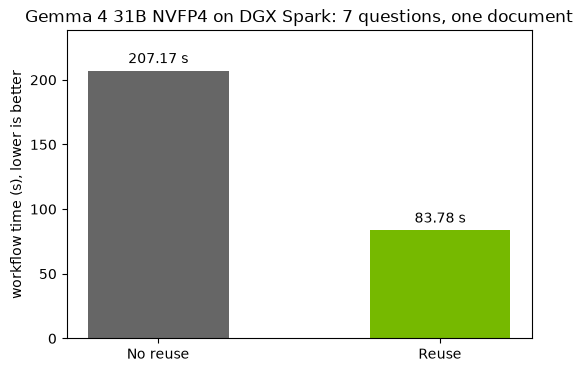

In [15]:
import matplotlib.pyplot as plt

no_reuse_s = sum(r["latency_s"] for r in no_reuse)
reuse_s = sum(r["latency_s"] for r in reuse)
doc_tokens = reuse[0]["prompt_tokens"]
grades = [grade(q, r["parsed"]) for q, r in zip(QUESTIONS, reuse)]
n = len(QUESTIONS)

rows = [
    ("Weights", f"{weights_gb:.1f} GB"),
    ("KV cache", f"{kv_cache_gb:.1f} GB, {kv_cache_tokens:,} tokens"),
    ("Document prompt", f"{doc_tokens:,} tokens"),
    ("Documents that fit in KV cache", f"{kv_cache_tokens // doc_tokens}"),
    ("Workflow time, no reuse", f"{no_reuse_s:.2f} s"),
    ("Workflow time, reuse", f"{reuse_s:.2f} s ({no_reuse_s / reuse_s:.1f}x faster)"),
    ("Schema-valid answers", f"{sum(r['parsed'] is not None for r in reuse)}/{n}"),
    ("Correct answers", f"{sum(c for c, _ in grades)}/{n}"),
    ("Grounded evidence", f"{sum(g is True for _, g in grades)}/{sum(g is not None for _, g in grades)}"),
]
display(Markdown("\n".join(["| Metric | Value |", "|---|---|"] + [f"| {a} | {b} |" for a, b in rows])))

fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(["No reuse", "Reuse"], [no_reuse_s, reuse_s], color=["#666666", "#76B900"], width=0.5)
ax.bar_label(bars, fmt="{:.2f} s", padding=3)
ax.set_title(f"Gemma 4 31B NVFP4 on DGX Spark: {n} questions, one document")
ax.set_ylabel("workflow time (s), lower is better")
ax.margins(y=0.15)
plt.show()